# XGBoost Model:-

> Here is the complete BigQuery ML (BQML) pipeline to train an XGBoost (Extreme Gradient Boosting) regression model on the car_data.csv (Car Price Prediction) dataset to predict Selling_Price

# Important Concepts for XGBoost in BQML:-
1. **Engine**: BigQuery's BOOSTED_TREE_REGRESSOR runs native XGBoost under the hood.
2. **Feature Engineering**: We create a new feature car_age (2024−Year) which gives a much stronger linear & non-linear signal than raw calendar year.
3. **Key XGBoost Hyperparameters**:
    - max_iterations = 50: Total boosting rounds (number of sequential trees).
    - learn_rate = 0.08: Step size shrinkage (η) to prevent overfitting.
    - max_tree_depth = 5: Max tree depth.
    - subsample = 0.8: Subsample ratio of training instances.
    - early_stop = TRUE: Automatically stops boosting when validation loss stops improving.

# Complete Step by Step Guide for XGBoost Model:-

- **Step 1**: Create Schema / Dataset
```sql
-- Create a schema/dataset in the US region
CREATE SCHEMA IF NOT EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox`
OPTIONS(
  location = 'US'
);
```
> gcp-aiml-sandbox-rahuld-1234.student_sandbox.raw_car_data

---

- **Step 2**: Cleanse and Feature Engineer Data -> We drop the high-cardinality Car_Name, calculate car_age, and standardize numeric and categorical data types.
```sql
-- Cleanse data and calculate car age
CREATE OR REPLACE TABLE `gcp-aiml-sandbox-rahuld-1234.student_sandbox.cleaned_car_data` AS
SELECT
  -- Feature Engineering: Calculate vehicle age (assuming base year 2024)
  (2024 - CAST(Year AS INT64)) AS car_age,
  
  -- Numeric Features
  CAST(Present_Price AS FLOAT64) AS Present_Price,  -- Ex-showroom price (in Lakhs)
  CAST(Kms_Driven AS INT64) AS Kms_Driven,
  CAST(Owner AS INT64) AS Owner,                    -- Number of previous owners (0, 1, 3)
  
  -- Categorical Features (Auto One-Hot Encoded by BQML)
  CAST(Fuel_Type AS STRING) AS Fuel_Type,           -- Petrol, Diesel, CNG
  CAST(Seller_Type AS STRING) AS Seller_Type,       -- Dealer, Individual
  CAST(Transmission AS STRING) AS Transmission,     -- Manual, Automatic
  
  -- Target Label to Predict
  CAST(Selling_Price AS FLOAT64) AS Selling_Price   -- Selling price (in Lakhs)
FROM
  `gcp-aiml-sandbox-rahuld-1234.student_sandbox.raw_car_data`;
```

---

- **Step 3**: Train the XGBoost Model (BOOSTED_TREE_REGRESSOR)
```sql
-- Train native XGBoost Regressor
CREATE OR REPLACE MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.car_price_xgb_model`
OPTIONS (
  model_type = 'BOOSTED_TREE_REGRESSOR',
  input_label_cols = ['Selling_Price'],
  
  -- XGBoost Hyperparameters
  max_iterations = 50,          -- Number of boosting rounds
  learn_rate = 0.08,           -- Learning rate (eta)
  max_tree_depth = 5,          -- Tree depth
  subsample = 0.80,            -- Row subsample ratio per tree
  early_stop = TRUE,           -- Prevent overfitting automatically
  
  -- 80% train / 20% test split
  data_split_method = 'RANDOM',
  data_split_eval_fraction = 0.2
) AS
SELECT
  car_age,
  Present_Price,
  Kms_Driven,
  Owner,
  Fuel_Type,
  Seller_Type,
  Transmission,
  Selling_Price
FROM
  `gcp-aiml-sandbox-rahuld-1234.student_sandbox.cleaned_car_data`;
```

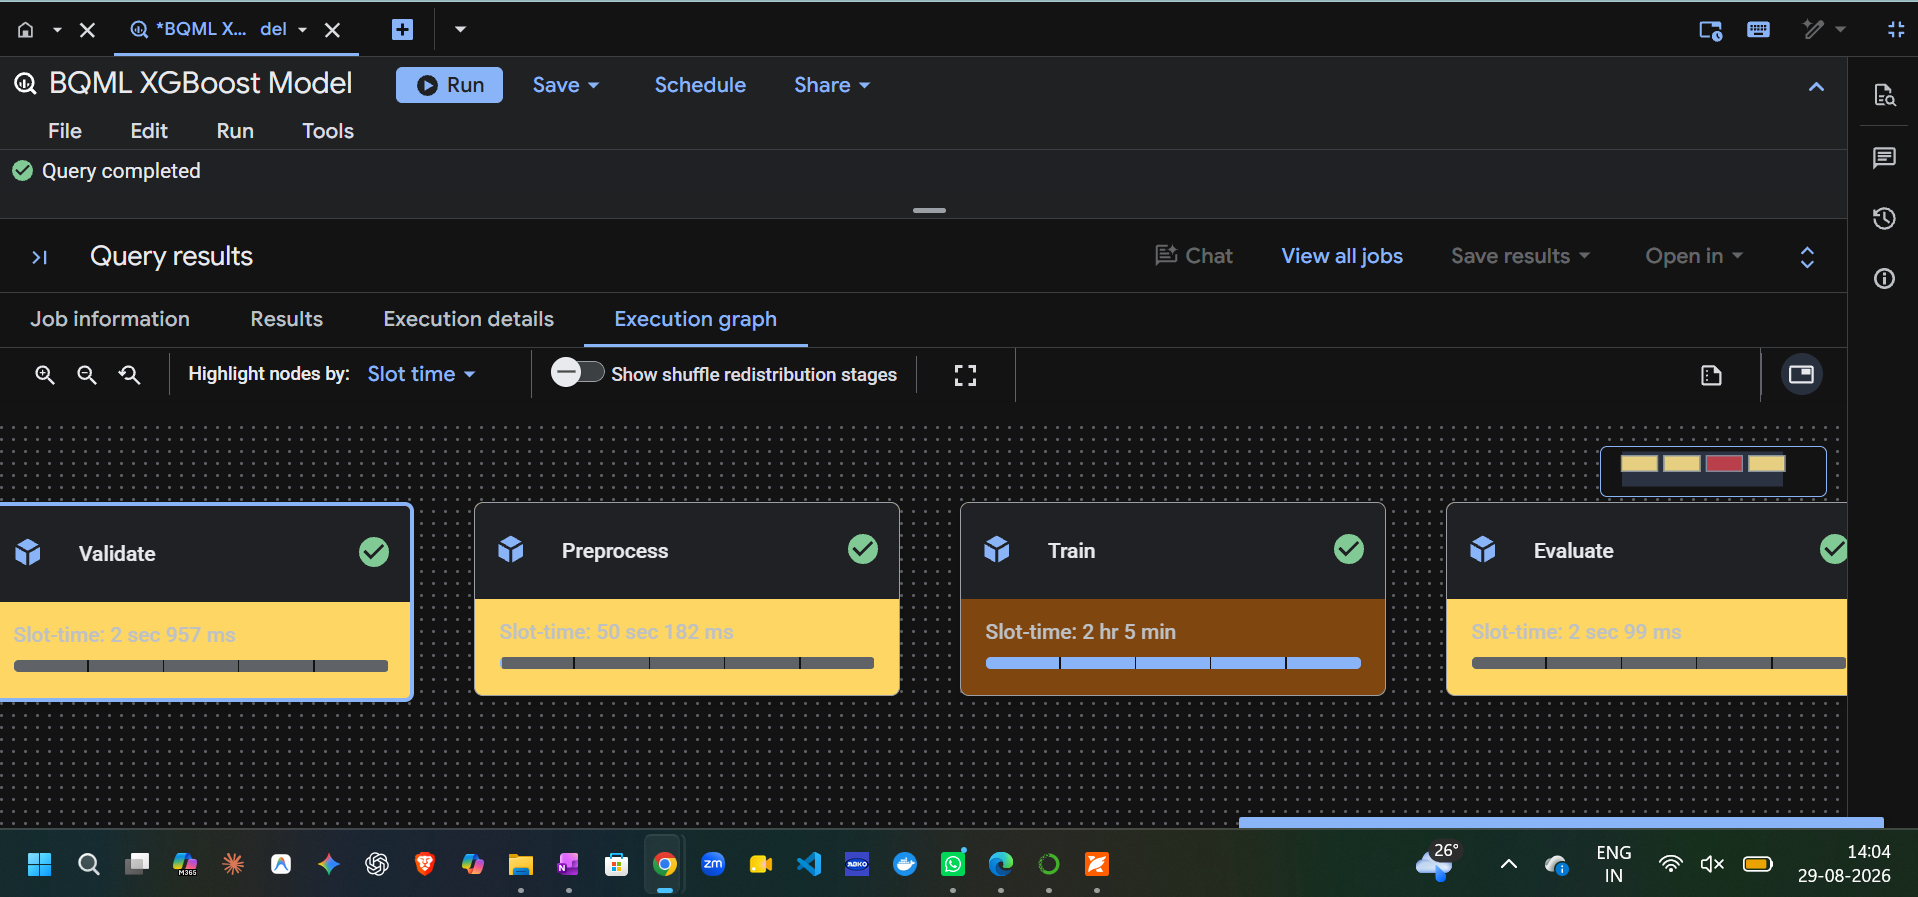

---


- **Step 4**: Evaluate Model Performance (R², MAE, RMSE) -> Evaluate the performance on the 20% unseen test split. An 
R2 > 0.85 is typical for XGBoost on this dataset.

```sql
-- Evaluate regression metrics
SELECT
  *
FROM
  ML.EVALUATE(MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.car_price_xgb_model`);
```
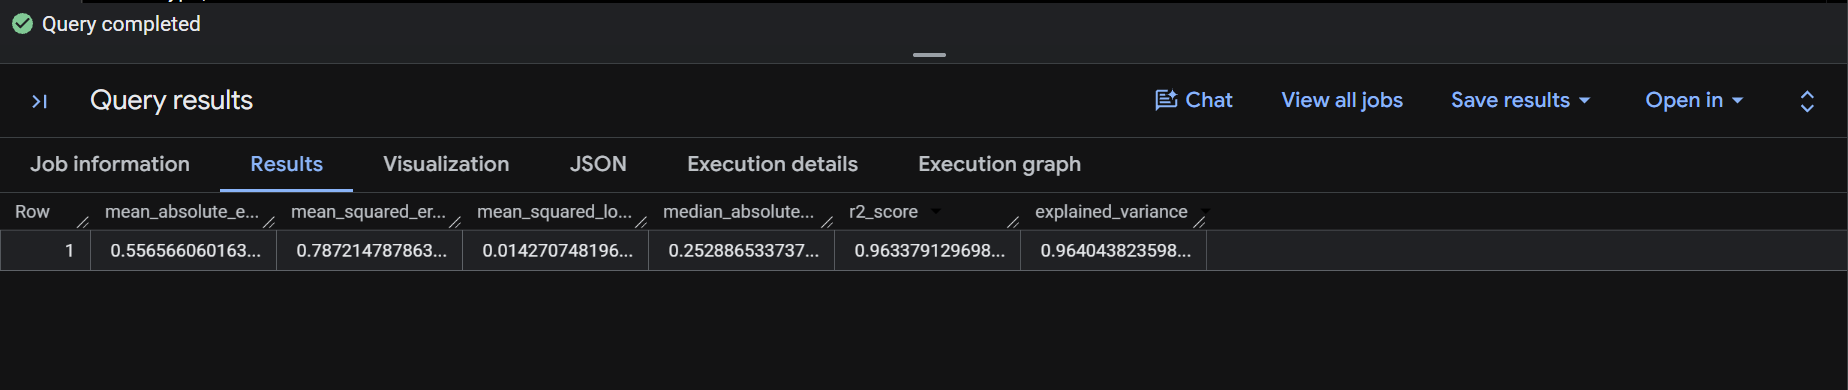

---

- **Step 5**: Feature Importance (Which features drive price?) -> Inspect which vehicle specifications contribute most to boosting gain (typically Present_Price, car_age, and Transmission).
```sql
-- Feature Importance in XGBoost trees
SELECT
  feature,
  importance_gain,
  importance_weight
FROM
  ML.FEATURE_IMPORTANCE(MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.car_price_xgb_model`)
ORDER BY
  importance_gain DESC;
```
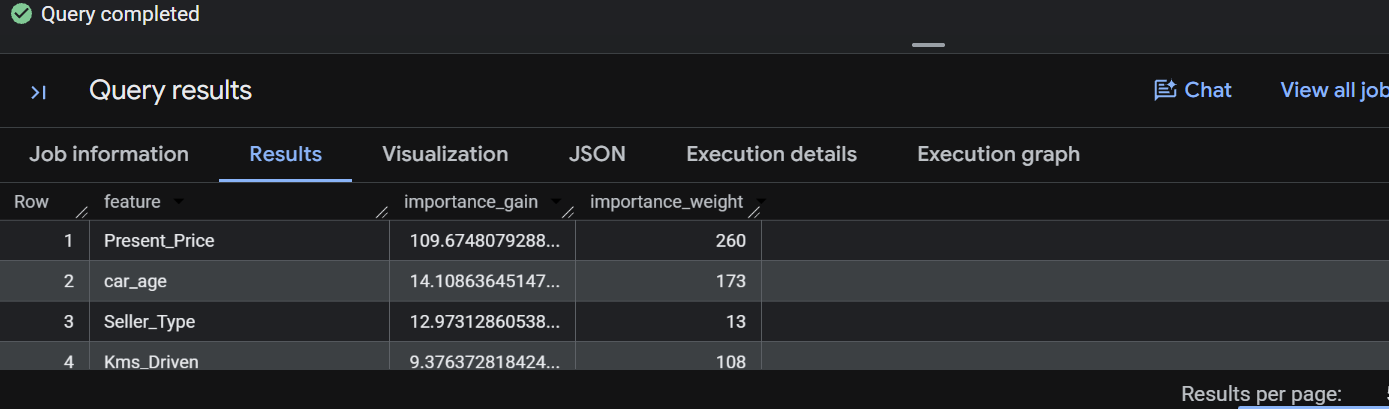

---


- **Step 6**: Make Car Price Predictions on Unseen Cars -> We test the model with two hypothetical vehicles:

    - **Car 1**: 4-year-old Diesel SUV, high original price (9.54), low mileage, dealer sold.
    - **Car 2**: 10-year-old Petrol Hatchback, low original price (5.59), high mileage, individual sold.
```sql
-- Predict selling price for new cars
SELECT
  ROUND(predicted_Selling_Price, 2) AS predicted_selling_price_lakhs,
  car_age,
  Present_Price,
  Kms_Driven,
  Fuel_Type,
  Transmission,
  Seller_Type
FROM
  ML.PREDICT(
    MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.car_price_xgb_model`,
    (
      -- Car 1: Premium Diesel SUV
      SELECT
        CAST(4 AS INT64) AS car_age,
        CAST(9.54 AS FLOAT64) AS Present_Price,
        CAST(27000 AS INT64) AS Kms_Driven,
        CAST(0 AS INT64) AS Owner,
        CAST('Diesel' AS STRING) AS Fuel_Type,
        CAST('Dealer' AS STRING) AS Seller_Type,
        CAST('Manual' AS STRING) AS Transmission
      UNION ALL
      -- Car 2: Older Budget Petrol Hatchback
      SELECT
        CAST(10 AS INT64) AS car_age,
        CAST(5.59 AS FLOAT64) AS Present_Price,
        CAST(75000 AS INT64) AS Kms_Driven,
        CAST(1 AS INT64) AS Owner,
        CAST('Petrol' AS STRING) AS Fuel_Type,
        CAST('Individual' AS STRING) AS Seller_Type,
        CAST('Manual' AS STRING) AS Transmission
    )
  );
```
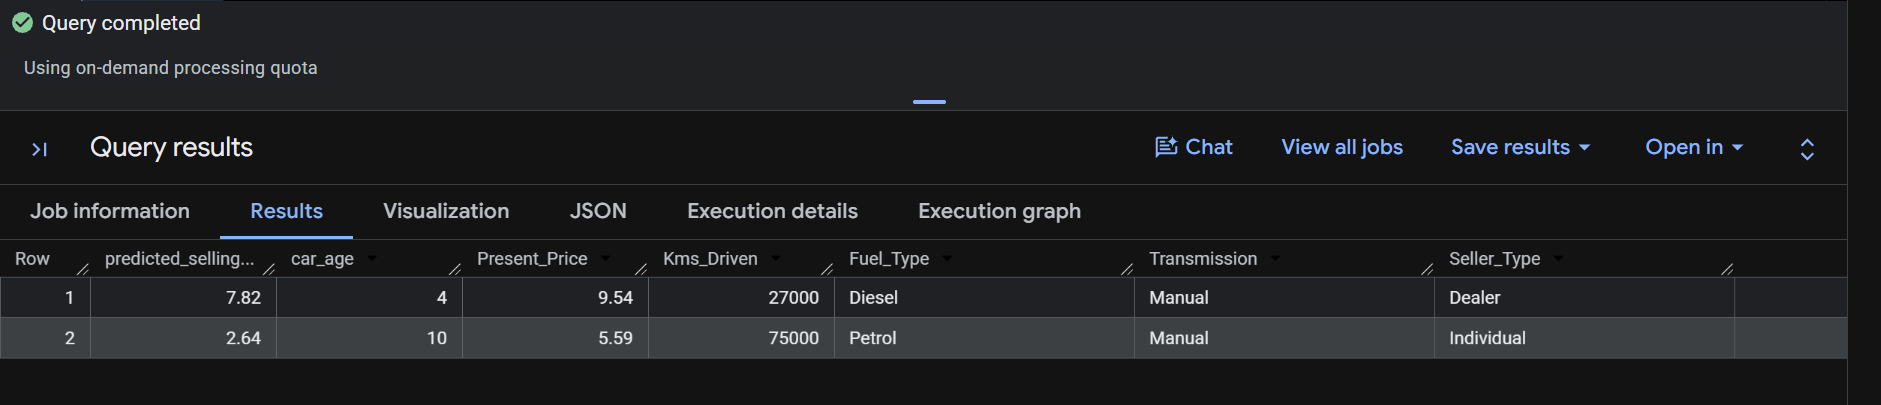



---


- **Step 7**: Clean Up Resources (Optional)
```sql
-- Cleanup resources
DROP MODEL IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox.car_price_xgb_model`;
DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox.cleaned_car_data`;
DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox.raw_car_data`;
DROP SCHEMA IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox` CASCADE;
```

---
